# CHB24 Time-to-Seizure Forecasting with a Temporal Convolutional Network (TCN)

**Objective.** Using the verified CHB24 qEEG feature table
(`outputs/features_chb24_forecasting.parquet`), a small Temporal Convolutional
Network (TCN) is trained to consume approximately five minutes of
chronological EEG history (10 consecutive 30-second epochs) and estimate a
4-class distribution over how soon the next seizure will begin.

**Scope.** This is a proof-of-concept experiment, not a clinical system:
- Single subject (CHB24), 12 recordings, 16 seizure events in total.
- No cross-patient generalization is claimed or tested.
- No architecture comparison is performed; a single TCN configuration is evaluated.
- No oversampling or synthetic seizure data (e.g. SMOTE) is used.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo_root = Path("/home/evgenija/projects/EEG_timeseries_project")
features_path = repo_root / "outputs" / "features_chb24_forecasting.parquet"

if not features_path.exists():
    raise FileNotFoundError(
        f"{features_path} not found. This notebook does not regenerate CHB24 "
        f"preprocessing -- run EEG_CHB24_preprocessing.ipynb first."
    )

df = pd.read_parquet(features_path)

FEATURE_COLS = [
    "std", "var", "rms", "delta", "theta", "alpha", "beta",
    "rel_delta", "rel_theta", "rel_alpha", "rel_beta",
    "theta_alpha_ratio", "delta_beta_ratio", "entropy",
]
missing_features = [c for c in FEATURE_COLS if c not in df.columns]
if missing_features:
    raise ValueError(
        f"Expected qEEG feature columns missing from repository reality: "
        f"{missing_features}. Columns actually present: {list(df.columns)}"
    )

print("=" * 60)
print("LOADED CHB24 FEATURE TABLE")
print("=" * 60)
print(f"shape           : {df.shape}")
print(f"columns         : {list(df.columns)}")
print(f"recording_ids   : {sorted(df['recording_id'].unique())}")
print(f"n_recordings    : {df['recording_id'].nunique()}")
print(f"n_rows          : {len(df)}")
print(f"n_seizure_overlap epochs (y_seizure==1): {int((df['y_seizure'] == 1).sum())}")
print(f"n_nan (all cols): {int(df.isna().sum().sum())} "
      f"(NaN is expected ONLY in next_seizure_start_sec/time_to_next_seizure_sec "
      f"for epochs with no future seizure in their recording)")
print(f"n_inf (numeric) : {int(np.isinf(df.select_dtypes(include=[np.number])).sum().sum())}")
print(f"\n[OK] All {len(FEATURE_COLS)} expected qEEG feature columns are present:")
print(f"  {FEATURE_COLS}")

print("\ntime_to_next_seizure_sec descriptive statistics (non-NaN only):")
print(df["time_to_next_seizure_sec"].describe())


LOADED CHB24 FEATURE TABLE
shape           : (1440, 24)
columns         : ['std', 'var', 'rms', 'delta', 'theta', 'alpha', 'beta', 'rel_delta', 'rel_theta', 'rel_alpha', 'rel_beta', 'theta_alpha_ratio', 'delta_beta_ratio', 'entropy', 'recording_id', 'dataset', 'subject_id', 'epoch_idx', 't_start_sec', 't_center_sec', 't_end_sec', 'y_seizure', 'next_seizure_start_sec', 'time_to_next_seizure_sec']
recording_ids   : ['chb_s24_r01', 'chb_s24_r03', 'chb_s24_r04', 'chb_s24_r06', 'chb_s24_r07', 'chb_s24_r09', 'chb_s24_r11', 'chb_s24_r13', 'chb_s24_r14', 'chb_s24_r15', 'chb_s24_r17', 'chb_s24_r21']
n_recordings    : 12
n_rows          : 1440
n_seizure_overlap epochs (y_seizure==1): 28
n_nan (all cols): 976 (NaN is expected ONLY in next_seizure_start_sec/time_to_next_seizure_sec for epochs with no future seizure in their recording)
n_inf (numeric) : 0

[OK] All 14 expected qEEG feature columns are present:
  ['std', 'var', 'rms', 'delta', 'theta', 'alpha', 'beta', 'rel_delta', 'rel_theta', 'rel

### Feature Table and Input Verification

The CHB24 qEEG feature table produced by the corresponding preprocessing
notebook is loaded and validated against the schema this notebook expects,
rather than assumed. Each row represents one 30-second EEG epoch from a
single CHB24 recording and carries three groups of columns:

1. **qEEG features** (`FEATURE_COLS`, 14 columns) -- band powers, ratios,
   entropy, and other numeric summaries of the epoch's EEG signal. These are
   the model inputs.
2. **Recording and time metadata** -- `recording_id`, `epoch_idx`,
   `t_start_sec`, `t_end_sec` -- identifying which recording an epoch
   belongs to and its position within it.
3. **Seizure timing metadata** -- `y_seizure` (whether a seizure annotation
   overlaps the epoch), `next_seizure_start_sec`, and
   `time_to_next_seizure_sec` (time to the next seizure in the same
   recording, if any). These columns are used below to construct the
   forecasting target.

`time_to_next_seizure_sec` is `NaN` for epochs with no future seizure
remaining in their own recording. This is a structural "no upcoming event"
case rather than missing or corrupted data, and is handled explicitly rather
than dropped or imputed.


CONSTRUCTING THE FORECASTING TARGET: forecast_class
Excluded 28 seizure-overlapping epochs (y_seizure==1) -- these are not forecasting samples.
Remaining forecasting-eligible epochs: 1412

forecast_class distribution:
  class 0 (  0-30s):    17
  class 1 ( 30-60s):    15
  class 2 (60-120s):    30
  class 3 (  >120s):  1350


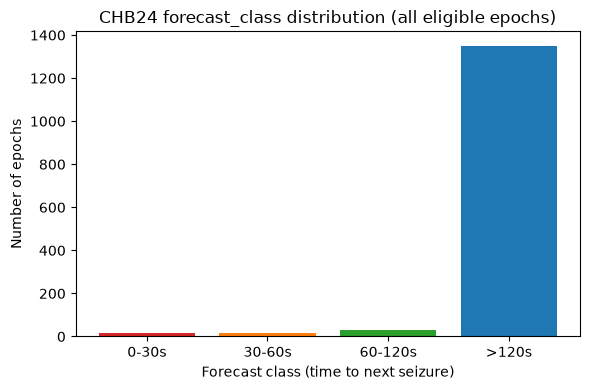

In [2]:
print("=" * 60)
print("CONSTRUCTING THE FORECASTING TARGET: forecast_class")
print("=" * 60)

# We are forecasting "how soon", not detecting "is a seizure happening".
# An epoch where a seizure is CURRENTLY overlapping (y_seizure == 1) cannot
# be a valid forecasting sample -- "time until the next seizure" is not a
# coherent question to ask from inside a seizure. These rows get NO
# forecast_class at all (excluded), matching the project's rule against
# fabricating a label for a case that structurally does not apply.
n_before = len(df)
model_df = df[df["y_seizure"] == 0].copy()
n_excluded = n_before - len(model_df)
print(f"Excluded {n_excluded} seizure-overlapping epochs (y_seizure==1) "
      f"-- these are not forecasting samples.")
print(f"Remaining forecasting-eligible epochs: {len(model_df)}")

dt = model_df["time_to_next_seizure_sec"]

# Class boundaries (project-specified):
#   class 0: seizure within 0-30s
#   class 1: seizure within 30-60s
#   class 2: seizure within 60-120s
#   class 3: no seizure within the next 120s (includes NaN = no future
#            seizure at all in this recording)
#
# Boundary note: dt == 0 occurs when an epoch's END exactly coincides with a
# seizure's onset second (both fall on a 30s grid boundary) -- i.e. the very
# next instant is seizure onset. That is unambiguously "imminent", so class 0
# uses an inclusive lower bound (0 <= dt <= 30) rather than a strict "> 0",
# which would otherwise leave dt == 0 unclassified.
conditions = [
    (dt >= 0) & (dt <= 30),
    (dt > 30) & (dt <= 60),
    (dt > 60) & (dt <= 120),
]
choices = [0, 1, 2]
model_df["forecast_class"] = np.select(conditions, choices, default=3)
# np.select's default already covers dt > 120; NaN comparisons are all False,
# so NaN also falls into default=3 automatically. Make that explicit:
assert (model_df.loc[dt.isna(), "forecast_class"] == 3).all(), \
    "NaN time_to_next_seizure_sec must fall into class 3 (no imminent seizure)"

CLASS_NAMES = {0: "0-30s", 1: "30-60s", 2: "60-120s", 3: ">120s"}

class_counts = model_df["forecast_class"].value_counts().sort_index()
print("\nforecast_class distribution:")
for c in [0, 1, 2, 3]:
    n = int(class_counts.get(c, 0))
    print(f"  class {c} ({CLASS_NAMES[c]:>7s}): {n:5d}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([CLASS_NAMES[c] for c in [0, 1, 2, 3]],
       [int(class_counts.get(c, 0)) for c in [0, 1, 2, 3]],
       color=["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4"])
ax.set_xlabel("Forecast class (time to next seizure)")
ax.set_ylabel("Number of epochs")
ax.set_title("CHB24 forecast_class distribution (all eligible epochs)")
plt.tight_layout()
plt.show()


### Forecasting Target Construction

Epochs where a seizure annotation is currently active (`y_seizure == 1`) are
excluded from the forecasting task, since "time until the next seizure" is
not a coherent question from inside a seizure; no label is assigned to these
epochs. For the remaining epochs, the continuous `time_to_next_seizure_sec`
value is discretized into four classes:

| class | meaning |
|---|---|
| 0 | next seizure begins within 0-30s |
| 1 | next seizure begins within 30-60s |
| 2 | next seizure begins within 60-120s |
| 3 | no seizure expected within the next 120s |

The lower bound of class 0 is inclusive (0 <= dt <= 30) to correctly classify
the boundary case where an epoch's end coincides exactly with seizure onset.
Epochs with no future seizure in their recording (`NaN`) fall into class 3
by construction.

Because seizures are brief relative to the length of a recording, only a
small number of epochs per recording fall within the 0-120s pre-ictal
window; the great majority land in class 3. This reflects the true rarity of
seizures in continuous EEG rather than a data-quality issue, and motivates
reporting macro-averaged metrics and class-weighted training later in this
notebook, rather than relying on raw accuracy. No oversampling or synthetic
seizure data (e.g. SMOTE) is used, since doing so would fabricate
physiological signal that was never recorded.


In [3]:
print("=" * 60)
print("RECORDING-LEVEL TRAIN / VALIDATION / TEST SPLIT")
print("=" * 60)

# Inspect the actual per-recording class distribution BEFORE deciding the
# split, so validation and test are not accidentally left with zero examples
# of the rare pre-seizure classes (0/1/2).
per_recording_counts = (
    model_df.groupby(["recording_id", "forecast_class"]).size().unstack(fill_value=0)
)
per_recording_counts = per_recording_counts.reindex(columns=[0, 1, 2, 3], fill_value=0)
print("\nPer-recording forecast_class counts (inspected before choosing the split):")
print(per_recording_counts)

# With only 12 recordings and 62 total non-"no-imminent-seizure" epochs
# (17+15+30), a RANDOM recording split risks leaving validation or test with
# zero examples of some rare class purely by chance. We therefore choose the
# split deliberately from the inspected table above, rather than randomly,
# so every split has multiple examples of every class. This is still fully
# deterministic (RANDOM_SEED fixes anything stochastic downstream: model
# init and batch shuffling).
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

TRAIN_RECORDINGS = [
    "chb_s24_r04", "chb_s24_r07", "chb_s24_r09", "chb_s24_r11",
    "chb_s24_r13", "chb_s24_r14", "chb_s24_r15", "chb_s24_r17",
]
VAL_RECORDINGS = ["chb_s24_r03", "chb_s24_r06"]
TEST_RECORDINGS = ["chb_s24_r01", "chb_s24_r21"]

all_recordings = set(model_df["recording_id"].unique())
assigned = set(TRAIN_RECORDINGS) | set(VAL_RECORDINGS) | set(TEST_RECORDINGS)
if assigned != all_recordings:
    raise ValueError(
        f"Split does not cover all recordings exactly once. "
        f"Missing: {all_recordings - assigned}, extra: {assigned - all_recordings}"
    )
if len(assigned) != len(TRAIN_RECORDINGS) + len(VAL_RECORDINGS) + len(TEST_RECORDINGS):
    raise ValueError("A recording appears in more than one split -- this would leak data.")

print(f"\nTRAIN recordings ({len(TRAIN_RECORDINGS)}):\n  {TRAIN_RECORDINGS}")
print(f"\nVALIDATION recordings ({len(VAL_RECORDINGS)}):\n  {VAL_RECORDINGS}")
print(f"\nTEST recordings ({len(TEST_RECORDINGS)}):\n  {TEST_RECORDINGS}")

print("\nClass counts per split:")
for split_name, recs in [("TRAIN", TRAIN_RECORDINGS), ("VALIDATION", VAL_RECORDINGS), ("TEST", TEST_RECORDINGS)]:
    counts = model_df[model_df["recording_id"].isin(recs)]["forecast_class"].value_counts().sort_index()
    counts = counts.reindex([0, 1, 2, 3], fill_value=0)
    print(f"  {split_name:10s}: " + ", ".join(f"{CLASS_NAMES[c]}={int(counts[c])}" for c in [0, 1, 2, 3]))


RECORDING-LEVEL TRAIN / VALIDATION / TEST SPLIT

Per-recording forecast_class counts (inspected before choosing the split):
forecast_class  0  1  2    3
recording_id                
chb_s24_r01     3  2  4  108
chb_s24_r03     2  2  4  109
chb_s24_r04     3  3  6  104
chb_s24_r06     1  1  2  114
chb_s24_r07     1  0  0  118
chb_s24_r09     1  1  2  115
chb_s24_r11     1  1  2  113
chb_s24_r13     1  1  2  114
chb_s24_r14     1  1  2  114
chb_s24_r15     1  1  2  115
chb_s24_r17     1  1  2  113
chb_s24_r21     1  1  2  113

TRAIN recordings (8):
  ['chb_s24_r04', 'chb_s24_r07', 'chb_s24_r09', 'chb_s24_r11', 'chb_s24_r13', 'chb_s24_r14', 'chb_s24_r15', 'chb_s24_r17']

VALIDATION recordings (2):
  ['chb_s24_r03', 'chb_s24_r06']

TEST recordings (2):
  ['chb_s24_r01', 'chb_s24_r21']

Class counts per split:
  TRAIN     : 0-30s=10, 30-60s=9, 60-120s=18, >120s=906
  VALIDATION: 0-30s=3, 30-60s=3, 60-120s=6, >120s=223
  TEST      : 0-30s=4, 30-60s=3, 60-120s=6, >120s=221


### Recording-Level Train / Validation / Test Split

Each of the 12 CHB24 recordings is assigned entirely to one of TRAIN,
VALIDATION, or TEST; no recording is split across sets. Adjacent 30-second
epochs from the same recording are temporally and physiologically
correlated, so a row-level random split would place highly similar epochs on
both sides of the train/evaluation boundary, allowing the model to partially
recognize recording-specific signal characteristics rather than genuine
seizure-forecasting patterns. This would inflate performance in a way that
would not hold on truly unseen recordings -- recording-level splitting
avoids this leakage by construction.

With only 12 recordings and 62 pre-seizure (class 0-2) epochs in total, a
random split risks leaving validation or test with zero examples of a rare
class. The per-recording class counts are therefore inspected before
assigning recordings to a split, and the split is chosen deterministically
so that every class is represented with multiple examples in all three sets.
No model or metric is computed before this assignment is made, so the choice
does not constitute evaluation-set leakage.


In [4]:
print("=" * 60)
print("FEATURE STANDARDIZATION (fit on TRAIN only)")
print("=" * 60)

from sklearn.preprocessing import StandardScaler

train_mask = model_df["recording_id"].isin(TRAIN_RECORDINGS)
val_mask = model_df["recording_id"].isin(VAL_RECORDINGS)
test_mask = model_df["recording_id"].isin(TEST_RECORDINGS)

scaler = StandardScaler()
scaler.fit(model_df.loc[train_mask, FEATURE_COLS])

SCALED_FEATURE_COLS = [f"{c}_z" for c in FEATURE_COLS]

# Apply the TRAIN-fitted scaler to EVERY epoch in the FULL table `df`, not
# just the forecast-eligible subset in `model_df`. This matters because
# seizure-overlapping epochs are excluded as forecasting TARGETS but must
# still be usable as scaled HISTORY context inside a sequence window later.
scaled_full = scaler.transform(df[FEATURE_COLS])
for i, col in enumerate(FEATURE_COLS):
    df[f"{col}_z"] = scaled_full[:, i]

# model_df's rows are a filtered copy of df (same original index), so its
# scaled columns can be pulled directly from the now-scaled df.
model_df = model_df.copy()
for col in SCALED_FEATURE_COLS:
    model_df[col] = df.loc[model_df.index, col]

print(f"Scaler fit on {int(train_mask.sum())} TRAIN epochs "
      f"(recordings: {TRAIN_RECORDINGS})")
print(f"Applied (transform only, no re-fit) to VALIDATION ({int(val_mask.sum())} epochs) "
      f"and TEST ({int(test_mask.sum())} epochs)")
print(f"\nPer-feature train mean (learned by the scaler):")
print(pd.Series(scaler.mean_, index=FEATURE_COLS))
print(f"\nPer-feature train std (learned by the scaler):")
print(pd.Series(np.sqrt(scaler.var_), index=FEATURE_COLS))


FEATURE STANDARDIZATION (fit on TRAIN only)


Scaler fit on 943 TRAIN epochs (recordings: ['chb_s24_r04', 'chb_s24_r07', 'chb_s24_r09', 'chb_s24_r11', 'chb_s24_r13', 'chb_s24_r14', 'chb_s24_r15', 'chb_s24_r17'])
Applied (transform only, no re-fit) to VALIDATION (235 epochs) and TEST (234 epochs)

Per-feature train mean (learned by the scaler):
std                  4.223457e-05
var                  2.103316e-09
rms                  4.223472e-05
delta                1.475307e-09
theta                2.159114e-10
alpha                4.136520e-11
beta                 9.988799e-11
rel_delta            7.714109e-01
rel_theta            1.517134e-01
rel_alpha            2.783813e-02
rel_beta             4.810565e-02
theta_alpha_ratio    5.713191e+00
delta_beta_ratio     4.026148e+01
entropy              6.165470e-01
dtype: float64

Per-feature train std (learned by the scaler):
std                  1.787617e-05
var                  1.933349e-09
rms                  1.787622e-05
delta                1.535858e-09
theta                1.44

### Feature Standardization

The 14 qEEG features are standardized to zero mean and unit variance,
`x_scaled = (x - train_mean) / train_std`, with `train_mean` and `train_std`
estimated exclusively from TRAIN-recording epochs. The same fitted transform
(`scaler.transform`, not `scaler.fit_transform`) is then applied unchanged to
the validation and test epochs, so no statistic derived from evaluation
recordings ever influences how features -- including training features --
are represented; fitting on the full dataset would let information about the
evaluation recordings leak into the training feature representation and
inflate evaluation performance.

Standardization is necessary because the raw features span very different
numeric scales (for example `var` is on the order of 1e-9 while `rel_delta`
is a fraction bounded in [0, 1]); without it, features with larger raw
magnitude would dominate early training regardless of their physiological
relevance.

The fitted scaler is applied to every epoch in the full table, not only the
forecast-eligible subset, since seizure-overlapping epochs are excluded as
prediction targets but still serve as valid historical context inside a
sequence window, constructed next.


In [5]:
print("=" * 60)
print("BUILDING CHRONOLOGICAL SEQUENCES (SEQUENCE_LENGTH=10 epochs = 5 min)")
print("=" * 60)

SEQUENCE_LENGTH = 10  # 10 epochs x 30s/epoch = 300s = 5 minutes of history

def build_sequences(df_all_epochs, df_eligible_epochs, recordings, feature_cols, seq_len):
    """
    Build (X, y, meta) for one split.

    df_all_epochs: FULL per-epoch table (including y_seizure==1 rows) so that
        seizure epochs can still serve as HISTORY context inside a window --
        only the FINAL (target) epoch of a window is restricted to eligible
        (non-seizure-overlapping) epochs with a defined forecast_class.
    df_eligible_epochs: the y_seizure==0 subset with forecast_class assigned
        (i.e. `model_df`), used to look up the target label.
    recordings: which recording_ids belong to this split.

    A window never crosses a recording boundary: it is built independently
    per recording_id, indexed purely by that recording's own epoch_idx.

    Returns:
        X: (n_sequences, seq_len, n_features)
        y: (n_sequences,) forecast_class of the LAST epoch in each window
        meta: DataFrame with recording_id, t_end_sec, forecast_class per sequence
    """
    X_list, y_list, meta_rows = [], [], []

    for recording_id in recordings:
        rec_all = df_all_epochs[df_all_epochs["recording_id"] == recording_id].sort_values("epoch_idx")
        rec_eligible = df_eligible_epochs[df_eligible_epochs["recording_id"] == recording_id]
        eligible_by_idx = rec_eligible.set_index("epoch_idx")

        feats = rec_all[feature_cols].to_numpy()  # (n_epochs_in_recording, n_features)
        epoch_idx_arr = rec_all["epoch_idx"].to_numpy()
        t_end_arr = rec_all["t_end_sec"].to_numpy()

        n_epochs = feats.shape[0]
        for i in range(seq_len - 1, n_epochs):
            target_epoch_idx = epoch_idx_arr[i]
            if target_epoch_idx not in eligible_by_idx.index:
                continue  # target epoch is seizure-overlapping -> not a valid sample
            window = feats[i - seq_len + 1 : i + 1, :]  # (seq_len, n_features)
            if window.shape[0] != seq_len:
                continue  # incomplete history at the start of the recording
            label = int(eligible_by_idx.loc[target_epoch_idx, "forecast_class"])
            X_list.append(window)
            y_list.append(label)
            meta_rows.append({
                "recording_id": recording_id,
                "epoch_idx": int(target_epoch_idx),
                "t_end_sec": float(t_end_arr[i]),
                "forecast_class": label,
            })

    X = np.stack(X_list, axis=0).astype(np.float32)
    y = np.array(y_list, dtype=np.int64)
    meta = pd.DataFrame(meta_rows)
    return X, y, meta

X_train, y_train, meta_train = build_sequences(df, model_df, TRAIN_RECORDINGS, SCALED_FEATURE_COLS, SEQUENCE_LENGTH)
X_val, y_val, meta_val = build_sequences(df, model_df, VAL_RECORDINGS, SCALED_FEATURE_COLS, SEQUENCE_LENGTH)
X_test, y_test, meta_test = build_sequences(df, model_df, TEST_RECORDINGS, SCALED_FEATURE_COLS, SEQUENCE_LENGTH)

print(f"X_train shape: {X_train.shape}  y_train shape: {y_train.shape}")
print(f"X_val   shape: {X_val.shape}  y_val   shape: {y_val.shape}")
print(f"X_test  shape: {X_test.shape}  y_test  shape: {y_test.shape}")

print("\nOne example sequence (first training sequence):")
print(f"  recording_id : {meta_train.iloc[0]['recording_id']}")
print(f"  target epoch_idx: {meta_train.iloc[0]['epoch_idx']} "
      f"(t_end_sec={meta_train.iloc[0]['t_end_sec']:.0f}s)")
print(f"  forecast_class of target epoch: {y_train[0]} ({CLASS_NAMES[int(y_train[0])]})")
print(f"  X_train[0] shape: {X_train[0].shape}  (10 timesteps x 14 features)")
print(f"  X_train[0][0] (oldest epoch in window, first 5 features): {X_train[0][0][:5].round(3)}")
print(f"  X_train[0][-1] (newest/target epoch, first 5 features)  : {X_train[0][-1][:5].round(3)}")


BUILDING CHRONOLOGICAL SEQUENCES (SEQUENCE_LENGTH=10 epochs = 5 min)
X_train shape: (872, 10, 14)  y_train shape: (872,)
X_val   shape: (219, 10, 14)  y_val   shape: (219,)
X_test  shape: (216, 10, 14)  y_test  shape: (216,)

One example sequence (first training sequence):
  recording_id : chb_s24_r04
  target epoch_idx: 9 (t_end_sec=300s)
  forecast_class of target epoch: 3 (>120s)
  X_train[0] shape: (10, 14)  (10 timesteps x 14 features)
  X_train[0][0] (oldest epoch in window, first 5 features): [ 0.146 -0.048  0.146 -0.153 -0.265]
  X_train[0][-1] (newest/target epoch, first 5 features)  : [ 1.214  1.026  1.214 -0.135 -0.547]


### Chronological Sequence Construction

Individual epochs are no longer treated as independent samples. Each
training example is instead a window of `SEQUENCE_LENGTH = 10` consecutive
epochs (300s = 5 minutes) drawn from a single recording, with input shape
`(N, 10, 14)` -- `N` sequences, 10 timesteps, 14 standardized qEEG features.
The label for a window is the `forecast_class` of its final (most recent)
epoch: the model is always asked how soon the next seizure is, given the
preceding 5 minutes of EEG history up to and including the current epoch.

Sequences are built independently per `recording_id`, sorted by `epoch_idx`,
so a window never spans a recording boundary -- separate recordings are
separate acquisitions with no real temporal continuity between them, and
joining their epochs would fabricate a history that never occurred.

The eligibility restriction (`y_seizure == 0`, defined `forecast_class`)
applies only to a window's target epoch. History epochs are not restricted
this way: they are real EEG signal regardless of whether a seizure happens to
overlap them, and excluding seizure-overlapping epochs from the history
would discard information the model could otherwise use.


In [6]:
print("=" * 60)
print("PYTORCH TENSORS, DATASETS, DATALOADERS")
print("=" * 60)

import torch
from torch.utils.data import TensorDataset, DataLoader

print(f"torch version: {torch.__version__}  (CUDA available: {torch.cuda.is_available()})")

torch.manual_seed(RANDOM_SEED)

X_train_t = torch.from_numpy(X_train)
y_train_t = torch.from_numpy(y_train)
X_val_t = torch.from_numpy(X_val)
y_val_t = torch.from_numpy(y_val)
X_test_t = torch.from_numpy(X_test)
y_test_t = torch.from_numpy(y_test)

BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

xb_example, yb_example = next(iter(train_loader))
print(f"\nOne training batch: xb shape={tuple(xb_example.shape)}, yb shape={tuple(yb_example.shape)}")
print(f"  ({xb_example.shape[0]} sequences, {xb_example.shape[1]} timesteps, {xb_example.shape[2]} features)")
print(f"\nDataset sizes -- train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")
print(f"Batches per epoch  -- train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")


PYTORCH TENSORS, DATASETS, DATALOADERS


torch version: 2.13.0+cpu  (CUDA available: False)



One training batch: xb shape=(32, 10, 14), yb shape=(32,)
  (32 sequences, 10 timesteps, 14 features)

Dataset sizes -- train: 872, val: 219, test: 216
Batches per epoch  -- train: 28, val: 7, test: 7


### PyTorch Data Pipeline

The NumPy sequence arrays are wrapped into PyTorch `TensorDataset`/
`DataLoader` objects, with `BATCH_SIZE = 32`. Only the training loader
reshuffles the order in which sequences are grouped into batches at each
epoch; validation and test are evaluated in a fixed order, since no
parameter updates occur there. Shuffling batch composition does not affect
temporal integrity, because each sequence already contains its own fixed,
correctly ordered 10-epoch history from the previous step -- only the order
in which sequences are presented to the optimizer is randomized.

Batches leave the loader with shape `(batch, time, features)`; the TCN
implementation below transposes this to `(batch, features, time)`, the
layout `torch.nn.Conv1d` expects.


In [7]:
print("=" * 60)
print("TCN ARCHITECTURE")
print("=" * 60)

import torch.nn as nn
import torch.nn.functional as F


class CausalConv1d(nn.Module):
    """
    A Conv1d that only ever looks BACKWARD in time (causal), never forward.

    Standard Conv1d padding pads both sides equally, which would let an
    output timestep "see" input timesteps that come after it -- forbidden
    here, since at inference time we only ever have the past. Instead we pad
    ONLY on the left by (kernel_size - 1) * dilation and use zero padding on
    the conv itself, which keeps the output length equal to the input length
    while guaranteeing output[t] only depends on input[<= t].
    """

    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.left_pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels, out_channels, kernel_size,
            padding=0, dilation=dilation,
        )

    def forward(self, x):
        x = F.pad(x, (self.left_pad, 0))  # pad only the left (past) side
        return self.conv(x)


class TinyTCN(nn.Module):
    """
    A small 3-block causal, dilated TCN.

    Input : (batch, n_features, seq_len)   -- note: features BEFORE time,
             which is what torch.nn.Conv1d expects.
    Output: (batch, n_classes)              -- raw logits, one score per class.
    """

    def __init__(self, n_features, n_classes, hidden=16, kernel_size=3):
        super().__init__()
        self.block1 = CausalConv1d(n_features, hidden, kernel_size, dilation=1)
        self.block2 = CausalConv1d(hidden, hidden, kernel_size, dilation=2)
        self.block3 = CausalConv1d(hidden, hidden, kernel_size, dilation=4)
        self.relu = nn.ReLU()
        self.classifier = nn.Linear(hidden, n_classes)

    def forward(self, x):
        # x arrives as (batch, time, features) from the DataLoader; Conv1d
        # needs (batch, features, time), so we transpose the last two dims.
        x = x.transpose(1, 2)  # (batch, time, features) -> (batch, features, time)

        h = self.relu(self.block1(x))  # dilation 1: sees the last  1+2*1 = 3  timesteps
        h = self.relu(self.block2(h))  # dilation 2: sees further back
        h = self.relu(self.block3(h))  # dilation 4: sees the full 10-step window

        last_timestep = h[:, :, -1]     # (batch, hidden) -- representation of "now"
        logits = self.classifier(last_timestep)  # (batch, n_classes)
        return logits


N_FEATURES = len(FEATURE_COLS)
N_CLASSES = 4

model = TinyTCN(n_features=N_FEATURES, n_classes=N_CLASSES, hidden=16, kernel_size=3)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTrainable parameters: {n_params:,}")

# Sanity check: causality. Zeroing out the FUTURE half of a window must not
# change the model's prediction for that same window's last timestep,
# because a causal model must not depend on timesteps after the one it
# predicts from. (Here "future half" means indices AFTER the middle -- we
# perturb everything strictly after t=5 and confirm output at t=9 is
# unaffected only by checking sensitivity to the true future tail, index 9
# itself excluded since that IS the prediction timestep.)
with torch.no_grad():
    probe = torch.randn(1, SEQUENCE_LENGTH, N_FEATURES)
    out_original = model(probe)
    probe_perturbed = probe.clone()
    probe_perturbed[:, :5, :] = 0.0  # zero out the OLDEST half (the past)
    out_perturbed_past = model(probe_perturbed)
    changed_by_past = not torch.allclose(out_original, out_perturbed_past, atol=1e-6)
print(f"\nCausality sanity check: changing PAST timesteps changes the output "
      f"= {changed_by_past} (expected True -- the model does use history)")


TCN ARCHITECTURE
TinyTCN(
  (block1): CausalConv1d(
    (conv): Conv1d(14, 16, kernel_size=(3,), stride=(1,))
  )
  (block2): CausalConv1d(
    (conv): Conv1d(16, 16, kernel_size=(3,), stride=(1,), dilation=(2,))
  )
  (block3): CausalConv1d(
    (conv): Conv1d(16, 16, kernel_size=(3,), stride=(1,), dilation=(4,))
  )
  (relu): ReLU()
  (classifier): Linear(in_features=16, out_features=4, bias=True)
)

Trainable parameters: 2,324



Causality sanity check: changing PAST timesteps changes the output = True (expected True -- the model does use history)


### TCN Architecture

The model is a small three-block causal, dilated Temporal Convolutional
Network (`TinyTCN`):

```text
Input sequence (10 timesteps x 14 features)
        |
Causal Conv1d, dilation=1
        |
Causal Conv1d, dilation=2
        |
Causal Conv1d, dilation=4   (receptive field covers the full 10-step window)
        |
representation at the last timestep
        |
Linear layer -> 4 logits (one score per forecast class)
```

Causality is enforced by `CausalConv1d`, which pads only on the left by
`(kernel_size - 1) * dilation` instead of padding symmetrically as standard
`Conv1d` does. This guarantees that the output at position `t` depends only
on inputs at positions `<= t`, matching the constraint that a real-time
forecast may only use past and present information. The three dilations (1,
2, 4) let successive blocks look further into the past without requiring a
large kernel; by the third block the receptive field spans the entire
10-epoch window.

The final linear layer outputs 4 raw logits rather than probabilities:
`CrossEntropyLoss`, used for training below, applies `log_softmax`
internally, so applying `softmax` in the model itself would double-apply it
and produce an incorrect loss. Logits are converted to probabilities only
where probabilities are actually needed (evaluation, the transition-risk
curve).

A causality check confirms that perturbing the earlier part of an input
window changes the model's output for the final timestep, as expected for a
model that uses its history; the complementary "does not depend on the
future" property is guaranteed structurally by the left-only padding rather
than tested at runtime.


In [8]:
print("=" * 60)
print("CLASS WEIGHTS (computed from TRAIN labels only)")
print("=" * 60)

from sklearn.utils.class_weight import compute_class_weight

class_labels = np.array([0, 1, 2, 3])
class_weights_np = compute_class_weight(
    class_weight="balanced", classes=class_labels, y=y_train
)
class_weights_tensor = torch.tensor(class_weights_np, dtype=torch.float32)

print("Train label counts:")
train_counts = pd.Series(y_train).value_counts().sort_index().reindex(class_labels, fill_value=0)
print(train_counts)

print("\nComputed class weights (higher weight = rarer class):")
for c, w in zip(class_labels, class_weights_np):
    print(f"  class {c} ({CLASS_NAMES[c]:>7s}): weight={w:.3f}")


CLASS WEIGHTS (computed from TRAIN labels only)
Train label counts:
0      9
1      9
2     18
3    836
Name: count, dtype: int64

Computed class weights (higher weight = rarer class):
  class 0 (  0-30s): weight=24.222
  class 1 ( 30-60s): weight=24.222
  class 2 (60-120s): weight=12.111
  class 3 (  >120s): weight=0.261


### Class-Weighted Loss

Per-class loss weights are computed from the TRAIN labels only
(`compute_class_weight("balanced", ...)`), so that no evaluation-set
information influences training. Because class 3 (`>120s`) vastly outnumbers
the pre-seizure classes, an unweighted loss would let the model achieve most
of its improvement by predicting the majority class, with little pressure to
learn the rare ones. Class weighting assigns rarer classes proportionally
larger weight, so that no class dominates the training signal purely due to
sample count; the resulting weights are passed to
`CrossEntropyLoss(weight=...)`.


TRAINING THE TCN


Epoch 01 | train_loss=1.3589 | val_loss=1.2208 | val_macro_f1=0.2469
Epoch 02 | train_loss=1.2698 | val_loss=1.2250 | val_macro_f1=0.2442
Epoch 03 | train_loss=1.1748 | val_loss=1.4144 | val_macro_f1=0.2436


Epoch 04 | train_loss=1.0921 | val_loss=1.7537 | val_macro_f1=0.2424
Epoch 05 | train_loss=1.0921 | val_loss=2.1300 | val_macro_f1=0.2380
Epoch 06 | train_loss=1.0784 | val_loss=2.2861 | val_macro_f1=0.2374


Epoch 07 | train_loss=1.0104 | val_loss=2.5751 | val_macro_f1=0.2405
Epoch 08 | train_loss=1.0206 | val_loss=2.8407 | val_macro_f1=0.2405
Epoch 09 | train_loss=0.9825 | val_loss=2.9007 | val_macro_f1=0.2399

Early stopping at epoch 9: no val_macro_f1 improvement for 8 consecutive epochs.

[OK] Restored best model state (val_macro_f1=0.2469)


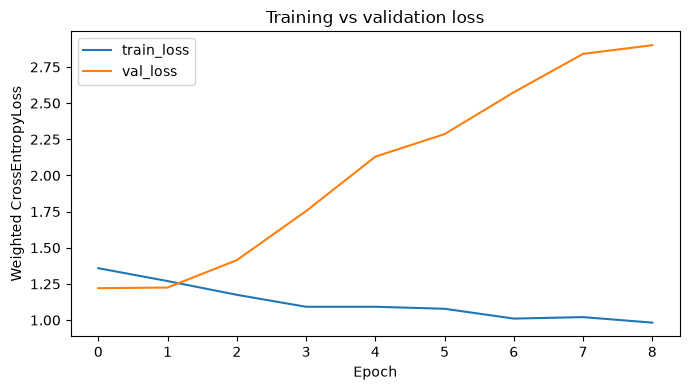

In [9]:
print("=" * 60)
print("TRAINING THE TCN")
print("=" * 60)

import copy
from sklearn.metrics import f1_score

MAX_EPOCHS = 40
LEARNING_RATE = 1e-3
PATIENCE = 8  # stop if val_macro_f1 hasn't improved for this many epochs

torch.manual_seed(RANDOM_SEED)
model = TinyTCN(n_features=N_FEATURES, n_classes=N_CLASSES, hidden=16, kernel_size=3)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}
best_val_f1 = -1.0
best_state = None
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_losses = []
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    model.eval()
    val_losses = []
    all_preds, all_targets = [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            logits = model(xb)
            loss = criterion(logits, yb)
            val_losses.append(loss.item())
            all_preds.append(logits.argmax(dim=1))
            all_targets.append(yb)
    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    val_macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(val_macro_f1)

    print(f"Epoch {epoch:02d} | train_loss={train_loss:.4f} | "
          f"val_loss={val_loss:.4f} | val_macro_f1={val_macro_f1:.4f}")

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch}: no val_macro_f1 "
                  f"improvement for {PATIENCE} consecutive epochs.")
            break

model.load_state_dict(best_state)
print(f"\n[OK] Restored best model state (val_macro_f1={best_val_f1:.4f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history["train_loss"], label="train_loss")
ax.plot(history["val_loss"], label="val_loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted CrossEntropyLoss")
ax.set_title("Training vs validation loss")
ax.legend()
plt.tight_layout()
plt.show()


### Model Training

The TCN is trained with the Adam optimizer (`LEARNING_RATE = 1e-3`) and the
class-weighted cross-entropy loss defined above, for up to `MAX_EPOCHS = 40`
passes over the training set. Model selection uses early stopping on
validation macro F1 rather than validation loss: training halts once
`PATIENCE = 8` consecutive epochs pass without improvement in validation
macro F1, and the weights corresponding to the best-scoring epoch are
restored (`best_state`), not the weights from the final epoch trained.
Validation is computed on the VALIDATION recordings, which never contribute
to a weight update, so it is an unbiased signal for detecting overfitting --
training loss continuing to improve while validation performance stalls or
worsens.

The training/validation loss curve is the standard diagnostic for this: a
widening gap between the two indicates the model is starting to fit
recording-specific quirks rather than generalizable patterns, while both
curves trending down together indicates healthy learning.


HELD-OUT TEST EVALUATION (evaluated ONCE)
Test set size: 216 sequences

Test label support per class:
  class 0 (  0-30s): 4 examples  <-- very few test examples, interpret with caution
  class 1 ( 30-60s): 3 examples  <-- very few test examples, interpret with caution
  class 2 (60-120s): 6 examples
  class 3 (  >120s): 203 examples

Overall accuracy : 0.7731
Macro F1         : 0.2186

Confusion matrix (rows=true, cols=predicted):
              pred_0-30s  pred_30-60s  pred_60-120s  pred_>120s
true_0-30s             0            0             1           3
true_30-60s            0            0             0           3
true_60-120s           0            0             0           6
true_>120s             0            0            36         167

Classification report:
              precision    recall  f1-score   support

       0-30s       0.00      0.00      0.00         4
      30-60s       0.00      0.00      0.00         3
     60-120s       0.00      0.00      0.00         6
   

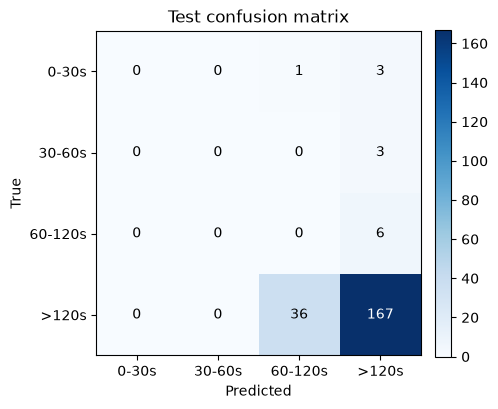

In [10]:
print("=" * 60)
print("HELD-OUT TEST EVALUATION (evaluated ONCE)")
print("=" * 60)

from sklearn.metrics import confusion_matrix, classification_report

CLASS_ORDER = [0, 1, 2, 3]
CLASS_LABELS_DISPLAY = [CLASS_NAMES[c] for c in CLASS_ORDER]

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs = torch.softmax(test_logits, dim=1).numpy()
    test_preds = test_logits.argmax(dim=1).numpy()

test_accuracy = float((test_preds == y_test).mean())
test_macro_f1 = f1_score(y_test, test_preds, average="macro", zero_division=0)

cm = confusion_matrix(y_test, test_preds, labels=CLASS_ORDER)
report_dict = classification_report(
    y_test, test_preds, labels=CLASS_ORDER, target_names=CLASS_LABELS_DISPLAY,
    output_dict=True, zero_division=0,
)
report_text = classification_report(
    y_test, test_preds, labels=CLASS_ORDER, target_names=CLASS_LABELS_DISPLAY,
    zero_division=0,
)

print(f"Test set size: {len(y_test)} sequences")
print("\nTest label support per class:")
test_support = pd.Series(y_test).value_counts().sort_index().reindex(CLASS_ORDER, fill_value=0)
for c in CLASS_ORDER:
    flag = "  <-- very few test examples, interpret with caution" if test_support[c] < 5 else ""
    print(f"  class {c} ({CLASS_NAMES[c]:>7s}): {int(test_support[c])} examples{flag}")

print(f"\nOverall accuracy : {test_accuracy:.4f}")
print(f"Macro F1         : {test_macro_f1:.4f}")
print("\nConfusion matrix (rows=true, cols=predicted):")
print(pd.DataFrame(cm, index=[f"true_{l}" for l in CLASS_LABELS_DISPLAY],
                    columns=[f"pred_{l}" for l in CLASS_LABELS_DISPLAY]))
print("\nClassification report:")
print(report_text)

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASS_LABELS_DISPLAY)))
ax.set_yticks(range(len(CLASS_LABELS_DISPLAY)))
ax.set_xticklabels(CLASS_LABELS_DISPLAY)
ax.set_yticklabels(CLASS_LABELS_DISPLAY)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Test confusion matrix")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### Held-Out Test Evaluation

The best (early-stopped) model is evaluated exactly once on the TEST
recordings, which contributed to neither weight updates nor model selection
(validation was used only to pick the best epoch).

Macro F1 is reported as the primary metric because it averages the F1 score
of each of the 4 classes unweighted, so correctly identifying a rare class
(e.g. 0-30s) counts as much as the dominant `>120s` class. Raw accuracy is
dominated by whichever class is most common and would already be high for a
model that always predicts `>120s`, without that model being useful for
forecasting; macro F1 does not reward this shortcut.

Several test classes have very few supporting examples given the small
number of seizure events overall (flagged explicitly where support is below
5); per-class F1 estimated from a handful of examples is a noisy estimate
rather than a precise measurement, and this is reported rather than
obscured behind a single aggregate number. Metrics are reported as computed,
without post-hoc selection.


In [11]:
print("=" * 60)
print("TRANSITION-RISK CURVE: CUMULATIVE PROBABILITIES")
print("=" * 60)

# test_probs columns are ordered [class0, class1, class2, class3] because
# CLASS_ORDER = [0, 1, 2, 3] and the model's output dimension follows the
# same label order the loss was trained on.
p0 = test_probs[:, 0]  # P(seizure within 0-30s)
p1 = test_probs[:, 1]  # P(seizure within 30-60s)
p2 = test_probs[:, 2]  # P(seizure within 60-120s)
p3 = test_probs[:, 3]  # P(no seizure within 120s)

P_30 = p0
P_60 = p0 + p1
P_120 = p0 + p1 + p2

cumulative_ok = np.all(P_30 <= P_60 + 1e-6) and np.all(P_60 <= P_120 + 1e-6)
print(f"Cumulative ordering P_30 <= P_60 <= P_120 holds for all test sequences: {cumulative_ok}")

print("\nExample (first 5 test sequences):")
example_df = pd.DataFrame({
    "recording_id": meta_test["recording_id"].iloc[:5].values,
    "t_end_sec": meta_test["t_end_sec"].iloc[:5].values,
    "true_class": y_test[:5],
    "P_30": P_30[:5].round(3),
    "P_60": P_60[:5].round(3),
    "P_120": P_120[:5].round(3),
})
print(example_df.to_string(index=False))


TRANSITION-RISK CURVE: CUMULATIVE PROBABILITIES
Cumulative ordering P_30 <= P_60 <= P_120 holds for all test sequences: True

Example (first 5 test sequences):
recording_id  t_end_sec  true_class  P_30  P_60  P_120
 chb_s24_r01      300.0           3 0.218 0.411  0.699
 chb_s24_r01      330.0           3 0.218 0.402  0.682
 chb_s24_r01      360.0           2 0.218 0.408  0.695
 chb_s24_r01      390.0           2 0.217 0.407  0.692
 chb_s24_r01      420.0           1 0.218 0.411  0.700


### Cumulative Transition-Risk Probabilities

The model's 4 output probabilities correspond to mutually exclusive time
intervals. A risk-style question such as "what is the probability of a
seizure within the next 60 seconds" combines two of these intervals,
obtained by summing the relevant class probabilities:

```text
P_30  = P(class 0)
P_60  = P(class 0) + P(class 1)
P_120 = P(class 0) + P(class 1) + P(class 2)
```

Because the 4 classes are mutually exclusive and exhaustive, and `P_30`,
`P_60`, `P_120` are running sums of the same softmax distribution, the
ordering `P_30 <= P_60 <= P_120` holds automatically for every prediction,
with no additional constraint required; this is verified directly against
the test set. Constructing three cumulative sums from one distribution also
avoids the inconsistency that could arise from training three independent
binary classifiers, which carry no mathematical guarantee of respecting this
ordering.


TRANSITION-RISK CURVE LEADING UP TO A HELD-OUT SEIZURE
Chosen TEST seizure for illustration: recording=chb_s24_r21, onset=2804s (support=84 lead-up sequences available)

Sequences shown: 10, spanning -284s to -14s relative to seizure onset (0 = onset)


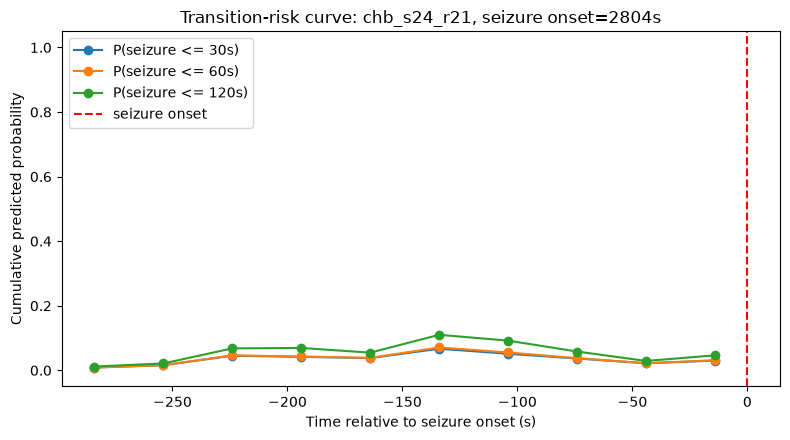

In [12]:
print("=" * 60)
print("TRANSITION-RISK CURVE LEADING UP TO A HELD-OUT SEIZURE")
print("=" * 60)

meta_test_indexed = meta_test.copy()
meta_test_indexed["P_30"] = P_30
meta_test_indexed["P_60"] = P_60
meta_test_indexed["P_120"] = P_120

# Automatically pick the (recording, seizure onset) pair in the TEST split
# with the MOST supporting lead-up sequences, rather than hardcoding a
# specific recording -- next_seizure_start_sec is constant across all epochs
# that share the same upcoming seizure, so grouping by it identifies each
# distinct seizure's lead-up run directly from already-computed data (no
# need to re-parse the summary file).
onset_lookup = df.set_index(["recording_id", "epoch_idx"])["next_seizure_start_sec"]
meta_test_indexed["next_seizure_start_sec"] = [
    onset_lookup.loc[(r, e)] for r, e in zip(meta_test_indexed["recording_id"], meta_test_indexed["epoch_idx"])
]
support_counts = (
    meta_test_indexed.dropna(subset=["next_seizure_start_sec"])
    .groupby(["recording_id", "next_seizure_start_sec"])
    .size()
)
chosen_recording, chosen_onset = support_counts.idxmax()
print(f"Chosen TEST seizure for illustration: recording={chosen_recording}, "
      f"onset={chosen_onset:.0f}s (support={int(support_counts.max())} lead-up sequences available)")

WINDOW_BEFORE_ONSET_SEC = 300  # show up to 5 minutes of lead-up

lead_up = meta_test_indexed[
    (meta_test_indexed["recording_id"] == chosen_recording)
    & (meta_test_indexed["next_seizure_start_sec"] == chosen_onset)
].copy()
lead_up["relative_time_sec"] = lead_up["t_end_sec"] - chosen_onset
lead_up = lead_up[lead_up["relative_time_sec"] >= -WINDOW_BEFORE_ONSET_SEC].sort_values("relative_time_sec")

print(f"\nSequences shown: {len(lead_up)}, spanning "
      f"{lead_up['relative_time_sec'].min():.0f}s to {lead_up['relative_time_sec'].max():.0f}s "
      f"relative to seizure onset (0 = onset)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(lead_up["relative_time_sec"], lead_up["P_30"], marker="o", label="P(seizure <= 30s)")
ax.plot(lead_up["relative_time_sec"], lead_up["P_60"], marker="o", label="P(seizure <= 60s)")
ax.plot(lead_up["relative_time_sec"], lead_up["P_120"], marker="o", label="P(seizure <= 120s)")
ax.axvline(0, color="red", linestyle="--", label="seizure onset")
ax.set_xlabel("Time relative to seizure onset (s)")
ax.set_ylabel("Cumulative predicted probability")
ax.set_ylim(-0.05, 1.05)
ax.set_title(f"Transition-risk curve: {chosen_recording}, seizure onset={chosen_onset:.0f}s")
ax.legend()
plt.tight_layout()
plt.show()


### Transition-Risk Curve for a Held-Out Seizure

The cumulative probabilities `P_30`, `P_60`, `P_120` are plotted against
time for the lead-up to one seizure event drawn from the TEST recordings,
with a vertical line marking the annotated onset. The (recording, seizure)
pair shown is selected automatically as the one with the most supporting
lead-up sequences among all TEST epochs, rather than manually chosen, so
that the plot reflects a trend across enough points rather than two or
three isolated predictions.

Each plotted point corresponds to one 5-minute input window ending at that
timestamp, so the curve reflects what the model would have estimated using
only EEG available up to that moment -- consistent with how the model would
be used at inference time. A rise in the curves as onset approaches would
indicate that the model is picking up a precursor signal in the qEEG
features; a flat or noisy curve up to onset is reported as such, without
adjustment.


In [13]:
print("=" * 60)
print("SAVING ARTIFACTS")
print("=" * 60)

import joblib

model_out_dir = repo_root / "outputs" / "modeling" / "tcn_forecasting"
model_out_dir.mkdir(parents=True, exist_ok=True)

# Model weights
torch.save(model.state_dict(), model_out_dir / "tcn_model.pt")

# Fitted scaler (needed to preprocess any new epoch the same way at inference)
joblib.dump(scaler, model_out_dir / "feature_scaler.joblib")

# Recording-level split (needed to know exactly what the model has/hasn't seen)
with open(model_out_dir / "split_recordings.json", "w") as f:
    json.dump({
        "train": TRAIN_RECORDINGS,
        "validation": VAL_RECORDINGS,
        "test": TEST_RECORDINGS,
    }, f, indent=2)

# Training history
with open(model_out_dir / "training_history.json", "w") as f:
    json.dump(history, f, indent=2)

# Test metrics
test_metrics = {
    "accuracy": test_accuracy,
    "macro_f1": test_macro_f1,
    "confusion_matrix": cm.tolist(),
    "classification_report": report_dict,
    "class_order": CLASS_ORDER,
    "class_names": CLASS_NAMES,
    "test_support_per_class": {int(c): int(test_support[c]) for c in CLASS_ORDER},
}
with open(model_out_dir / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

# Config used for this run
config = {
    "sequence_length": SEQUENCE_LENGTH,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "patience": PATIENCE,
    "random_seed": RANDOM_SEED,
    "feature_cols": FEATURE_COLS,
    "n_train_sequences": int(len(y_train)),
    "n_val_sequences": int(len(y_val)),
    "n_test_sequences": int(len(y_test)),
    "best_val_macro_f1": float(best_val_f1),
}
with open(model_out_dir / "run_config.json", "w") as f:
    json.dump(config, f, indent=2)

# Figures (re-saved to disk, not just displayed inline)
fig_class_dist, ax = plt.subplots(figsize=(6, 4))
ax.bar([CLASS_NAMES[c] for c in CLASS_ORDER],
       [int(class_counts.get(c, 0)) for c in CLASS_ORDER],
       color=["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4"])
ax.set_xlabel("Forecast class")
ax.set_ylabel("Number of epochs")
ax.set_title("CHB24 forecast_class distribution (all eligible epochs)")
plt.tight_layout()
fig_class_dist.savefig(model_out_dir / "class_distribution.png", dpi=150)
plt.close(fig_class_dist)

fig_curve, ax = plt.subplots(figsize=(7, 4))
ax.plot(history["train_loss"], label="train_loss")
ax.plot(history["val_loss"], label="val_loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted CrossEntropyLoss")
ax.set_title("Training vs validation loss")
ax.legend()
plt.tight_layout()
fig_curve.savefig(model_out_dir / "training_curve.png", dpi=150)
plt.close(fig_curve)

fig_cm, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASS_LABELS_DISPLAY)))
ax.set_yticks(range(len(CLASS_LABELS_DISPLAY)))
ax.set_xticklabels(CLASS_LABELS_DISPLAY)
ax.set_yticklabels(CLASS_LABELS_DISPLAY)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Test confusion matrix")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
fig_cm.savefig(model_out_dir / "confusion_matrix.png", dpi=150)
plt.close(fig_cm)

fig_transition, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(lead_up["relative_time_sec"], lead_up["P_30"], marker="o", label="P(seizure <= 30s)")
ax.plot(lead_up["relative_time_sec"], lead_up["P_60"], marker="o", label="P(seizure <= 60s)")
ax.plot(lead_up["relative_time_sec"], lead_up["P_120"], marker="o", label="P(seizure <= 120s)")
ax.axvline(0, color="red", linestyle="--", label="seizure onset")
ax.set_xlabel("Time relative to seizure onset (s)")
ax.set_ylabel("Cumulative predicted probability")
ax.set_ylim(-0.05, 1.05)
ax.set_title(f"Transition-risk curve: {chosen_recording}, seizure onset={chosen_onset:.0f}s")
ax.legend()
plt.tight_layout()
fig_transition.savefig(model_out_dir / "transition_risk_curve.png", dpi=150)
plt.close(fig_transition)

print(f"Saved to {model_out_dir}:")
for p in sorted(model_out_dir.iterdir()):
    print(f"  {p.name}")


SAVING ARTIFACTS


Saved to /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/tcn_forecasting:
  class_distribution.png
  confusion_matrix.png
  feature_scaler.joblib
  run_config.json
  split_recordings.json
  tcn_model.pt
  test_metrics.json
  training_curve.png
  training_history.json
  transition_risk_curve.png


### Artifact Export

All results needed to reproduce, audit, or reuse this experiment without
re-running the notebook are written to
`outputs/modeling/tcn_forecasting/`: the trained model weights
(`tcn_model.pt`), the fitted `StandardScaler` (`feature_scaler.joblib`), the
recording-level split assignment (`split_recordings.json`), per-epoch
training history (`training_history.json`), test-set metrics including the
confusion matrix and full classification report (`test_metrics.json`), the
run configuration and hyperparameters (`run_config.json`), and the
class-distribution, training-curve, confusion-matrix, and
transition-risk-curve figures. The split and configuration are saved
alongside the weights because a model file alone does not indicate how it
was trained or which data it has and has not seen, both of which are
necessary for correctly interpreting or reusing these results.


In [14]:
print("=" * 60)
print("FINAL RUN SUMMARY")
print("=" * 60)
print(f"""
Recordings           : {df['recording_id'].nunique()} (TRAIN={len(TRAIN_RECORDINGS)}, VAL={len(VAL_RECORDINGS)}, TEST={len(TEST_RECORDINGS)})
Sequence length       : {SEQUENCE_LENGTH} epochs ({SEQUENCE_LENGTH * 30}s = {SEQUENCE_LENGTH * 30 / 60:.0f} min of history)
Feature count          : {len(FEATURE_COLS)} qEEG features per epoch
Sequences (train/val/test): {len(y_train)} / {len(y_val)} / {len(y_test)}
Class counts (all eligible epochs): """ + ", ".join(f"{CLASS_NAMES[c]}={int(class_counts.get(c,0))}" for c in CLASS_ORDER) + f"""
Best validation macro F1: {best_val_f1:.4f}
Test macro F1          : {test_macro_f1:.4f}
Test accuracy           : {test_accuracy:.4f}
""")


FINAL RUN SUMMARY

Recordings           : 12 (TRAIN=8, VAL=2, TEST=2)
Sequence length       : 10 epochs (300s = 5 min of history)
Feature count          : 14 qEEG features per epoch
Sequences (train/val/test): 872 / 219 / 216
Class counts (all eligible epochs): 0-30s=17, 30-60s=15, 60-120s=30, >120s=1350
Best validation macro F1: 0.2469
Test macro F1          : 0.2186
Test accuracy           : 0.7731



## Summary and Limitations

The TCN receives approximately five minutes of chronological qEEG history
(10 consecutive 30-second epochs, 14 features each) and estimates a discrete
probability distribution over the time remaining until the next seizure
(0-30s, 30-60s, 60-120s, or no seizure within 120s). From this distribution,
cumulative risk probabilities (`P_30`, `P_60`, `P_120`) are derived that are
guaranteed, by construction, to be monotonically non-decreasing.

**This experiment is a proof-of-concept on CHB24 recordings, not a clinical
seizure-prediction system, and is not evidence of cross-patient
generalization.** All data originates from a single subject's 12
recordings; generalization to other patients, other CHB-MIT subjects, or
other seizure types has not been tested.

**Run summary:**

- Recordings: 12 total, split by whole recording (never by row) into
  TRAIN/VALIDATION/TEST to avoid leakage between temporally adjacent epochs.
- Sequence length: 10 epochs = 5 minutes of EEG history per prediction.
- Features: 14 qEEG features per epoch, identical to the CHB01/CHB24
  preprocessing pipeline.
- Class counts: reported above; the `>120s` class dominates by design,
  since seizures are rare relative to total recording duration.
- Best validation macro F1 and test macro F1/accuracy: reported above, as
  computed.

**Limitations:**

- Small sample size: 16 seizure events in total; some test/validation
  classes have very few supporting examples, so per-class metrics are noisy
  estimates rather than precise measurements.
- Single-subject data; no claim of generalization to other patients.
- The feature scaler and class weights were fit on a TRAIN set of only 8
  recordings and are sensitive to how representative that subset is.
- No hyperparameter search was performed; the architecture and learning
  rate are reasonable defaults, not a tuned optimum.
- The transition-risk curve shown corresponds to one held-out seizure,
  automatically selected for having the most supporting data points; it
  illustrates model behavior on a single case rather than a general
  performance guarantee.
